# Переобучение и календарные признаки

Теперь сравню CatBoost, обученный перед мартом, с ежемесячным переобучением. Отдельно уберу календарные признаки, сохранив параметры и временные окна. Так можно проверить, помогает ли модели сезонность, которую было видно в EDA.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent
REPORTS = ROOT / "reports/evaluation"
plt.rcParams.update(
    {"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False}
)

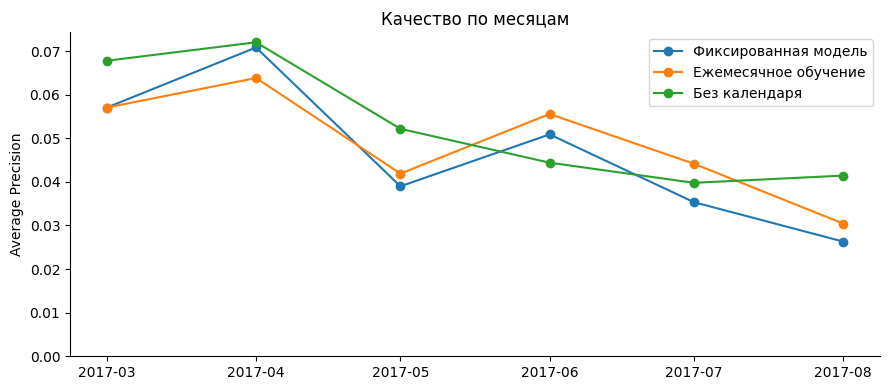

In [2]:
monthly = pd.read_csv(REPORTS / "monthly_metrics.csv", parse_dates=["month"])
names = {
    "catboost_frozen": "Фиксированная модель",
    "catboost_monthly": "Ежемесячное обучение",
    "catboost_no_calendar": "Без календаря",
}
fig, ax = plt.subplots()
for name, label in names.items():
    group = monthly.loc[monthly.model == name]
    ax.plot(group.month, group.average_precision, marker="o", label=label)
locator = mdates.MonthLocator()
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.set(ylabel="Average Precision", title="Качество по месяцам", ylim=(0, None))
ax.legend()
plt.tight_layout()
plt.show()

In [3]:
metrics = pd.read_csv(REPORTS / "test_metrics.csv").set_index("model")
metrics.loc[
    list(names),
    ["average_precision", "recall_at_budget", "precision_at_budget", "brier"],
].round(5)

,average_precision,recall_at_budget,precision_at_budget,brier
model,,,,
catboost_frozen,0.04314,0.21289,0.03673,0.01832
catboost_monthly,0.04364,0.23529,0.04060,0.01829
catboost_no_calendar,0.04539,0.23249,0.04012,0.01825


Переобучение немного подняло AP: с **0,0431** до **0,0436**. В список того же размера попало больше отмен: recall вырос с **21,3%** до **23,5%**. Но по месяцам преимущество меняется, поэтому одной итоговой таблицы недостаточно.

Без календаря AP составила **0,0454**, немного выше полного варианта. Сезонный рисунок на агрегированных графиках не дал явного выигрыша модели при этих настройках. Основной результат отчёта остаётся у конфигурации, выбранной на январе–феврале.

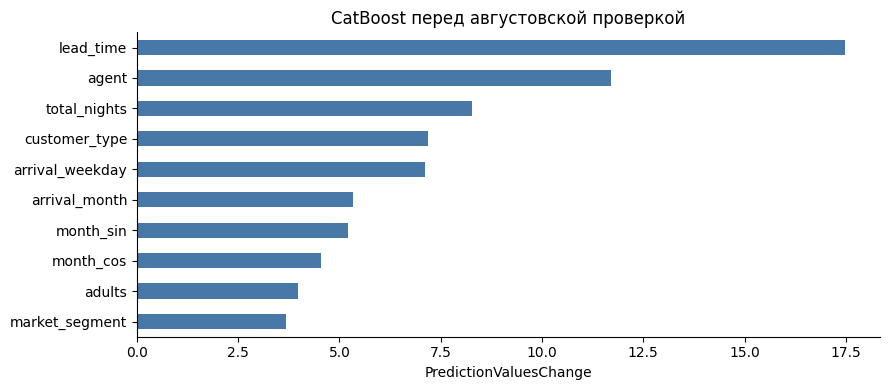

In [4]:
importance = pd.read_csv(REPORTS / "feature_importance.csv", index_col=0).iloc[:10]
ax = importance.iloc[::-1, 0].plot.barh(color="#4878a8")
ax.set(
    xlabel="PredictionValuesChange",
    ylabel="",
    title="CatBoost перед августовской проверкой",
)
plt.tight_layout()
plt.show()

## Разница между отелями

In [5]:
segments = pd.read_csv(REPORTS / "hotel_metrics.csv")
segments.query("model == 'catboost_monthly'")[
    [
        "hotel",
        "rows",
        "positive_rate",
        "average_precision",
        "precision_at_budget",
        "recall_at_budget",
    ]
].round(4)

,hotel,rows,positive_rate,average_precision,precision_at_budget,recall_at_budget
2,City Hotel,12597,0.0184,0.0473,0.0425,0.2457
3,Resort Hotel,6461,0.0193,0.0458,0.0371,0.2160


## Выводы

Ежемесячное обновление помогло найти больше поздних отмен при том же размере списка, но большого прироста AP не получилось. Календарные признаки тоже не дали устойчивого выигрыша. Простой линейный baseline остаётся полезным ориентиром.

Для этой задачи важнее аккуратно задать момент прогноза и доступность исходов, чем увеличивать число моделей. Данные покрывают только два отеля и чуть больше двух лет. Для дальнейшего выбора стратегии понадобились бы новые месяцы наблюдений.

Небольшая API-демонстрация возвращает вероятность поздней отмены для активной брони накануне заезда. Она использует ту же функцию подготовки признаков, что и обучение.